In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy.stats import chi2_contingency
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

In [6]:
df = pd.read_csv("C:\\Users\\gopir\\OneDrive\\Desktop\\WA_Fn-UseC_-HR-Employee-Attrition.csv")
print(f'Shape: {df.shape}')
df.head()

Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [8]:
df.describe().T.style.background_gradient(cmap='Blues', subset=['mean', 'std', 'max'])

,count,mean,std,min,25%,50%,75%,max
Age,1470.000000,36.923810,9.135373,18.000000,30.000000,36.000000,43.000000,60.000000
DailyRate,1470.000000,802.485714,403.509100,102.000000,465.000000,802.000000,1157.000000,1499.000000
DistanceFromHome,1470.000000,9.192517,8.106864,1.000000,2.000000,7.000000,14.000000,29.000000
Education,1470.000000,2.912925,1.024165,1.000000,2.000000,3.000000,4.000000,5.000000
EmployeeCount,1470.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
EmployeeNumber,1470.000000,1024.865306,602.024335,1.000000,491.250000,1020.500000,1555.750000,2068.000000
EnvironmentSatisfaction,1470.000000,2.721769,1.093082,1.000000,2.000000,3.000000,4.000000,4.000000
HourlyRate,1470.000000,65.891156,20.329428,30.000000,48.000000,66.000000,83.750000,100.000000
JobInvolvement,1470.000000,2.729932,0.711561,1.000000,2.000000,3.000000,3.000000,4.000000
JobLevel,1470.000000,2.063946,1.106940,1.000000,1.000000,2.000000,3.000000,5.000000


In [9]:
missing = df.isnull().sum()
print('Missing values per column:')
print(missing[missing > 0] if missing.any() else 'No missing values found.')

print(f'\nDuplicate rows: {df.duplicated().sum()}')

# Columns with a single constant value (no variance — drop candidates)
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print(f'Constant columns (no variance): {constant_cols}')
if constant_cols:
    df.drop(columns=constant_cols, inplace=True)
    print(f'Dropped: {constant_cols}')

Missing values per column:
No missing values found.

Duplicate rows: 0
Constant columns (no variance): ['EmployeeCount', 'Over18', 'StandardHours']
Dropped: ['EmployeeCount', 'Over18', 'StandardHours']


In [10]:
# Encode target for correlation analysis
df['Attrition_flag'] = (df['Attrition'] == 'Yes').astype(int)

num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include='object').columns.tolist()
print(f'Numerical columns ({len(num_cols)}): {num_cols}')
print(f'Categorical columns ({len(cat_cols)}): {cat_cols}')

Numerical columns (25): ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'Attrition_flag']
Categorical columns (8): ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


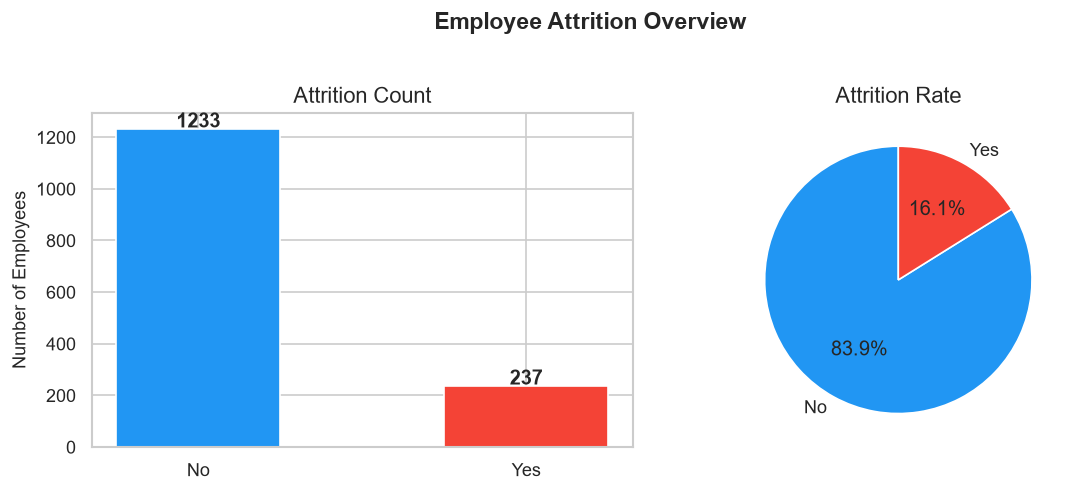

Attrition Rate: 16.12%  |  Retained: 83.88%


In [11]:
attrition_counts = df['Attrition'].value_counts()
attrition_pct = df['Attrition'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(attrition_counts.index, attrition_counts.values,
            color=['#2196F3', '#F44336'], edgecolor='white', width=0.5)
axes[0].set_title('Attrition Count')
axes[0].set_ylabel('Number of Employees')
for i, v in enumerate(attrition_counts.values):
    axes[0].text(i, v + 5, str(v), ha='center', fontweight='bold')

axes[1].pie(attrition_counts.values, labels=attrition_counts.index,
            autopct='%1.1f%%', colors=['#2196F3', '#F44336'],
            startangle=90, wedgeprops=dict(edgecolor='white'))
axes[1].set_title('Attrition Rate')

plt.suptitle('Employee Attrition Overview', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f'Attrition Rate: {attrition_pct["Yes"]:.2f}%  |  '
      f'Retained: {attrition_pct["No"]:.2f}%')

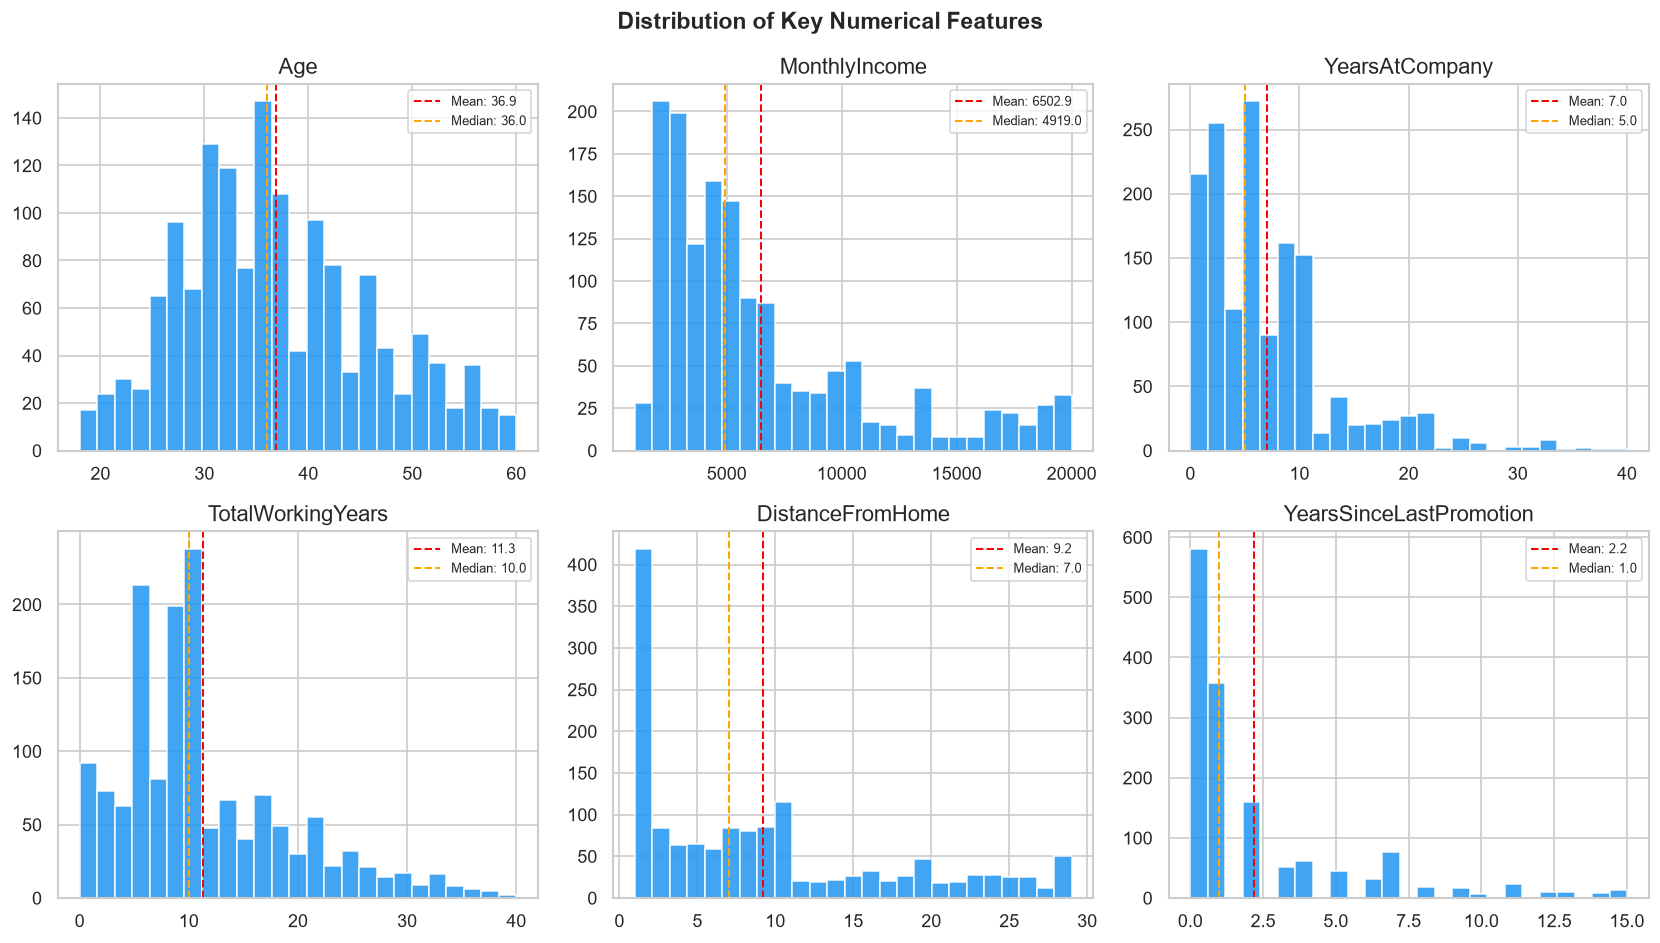

In [12]:
# Distributions of key numerical features
key_nums = ['Age', 'MonthlyIncome', 'YearsAtCompany', 'TotalWorkingYears',
            'DistanceFromHome', 'YearsSinceLastPromotion']

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(key_nums):
    axes[i].hist(df[col], bins=25, color='#2196F3', edgecolor='white', alpha=0.85)
    axes[i].axvline(df[col].mean(), color='red', linestyle='--', linewidth=1.2,
                    label=f'Mean: {df[col].mean():.1f}')
    axes[i].axvline(df[col].median(), color='orange', linestyle='--', linewidth=1.2,
                    label=f'Median: {df[col].median():.1f}')
    axes[i].set_title(col)
    axes[i].legend(fontsize=8)

plt.suptitle('Distribution of Key Numerical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

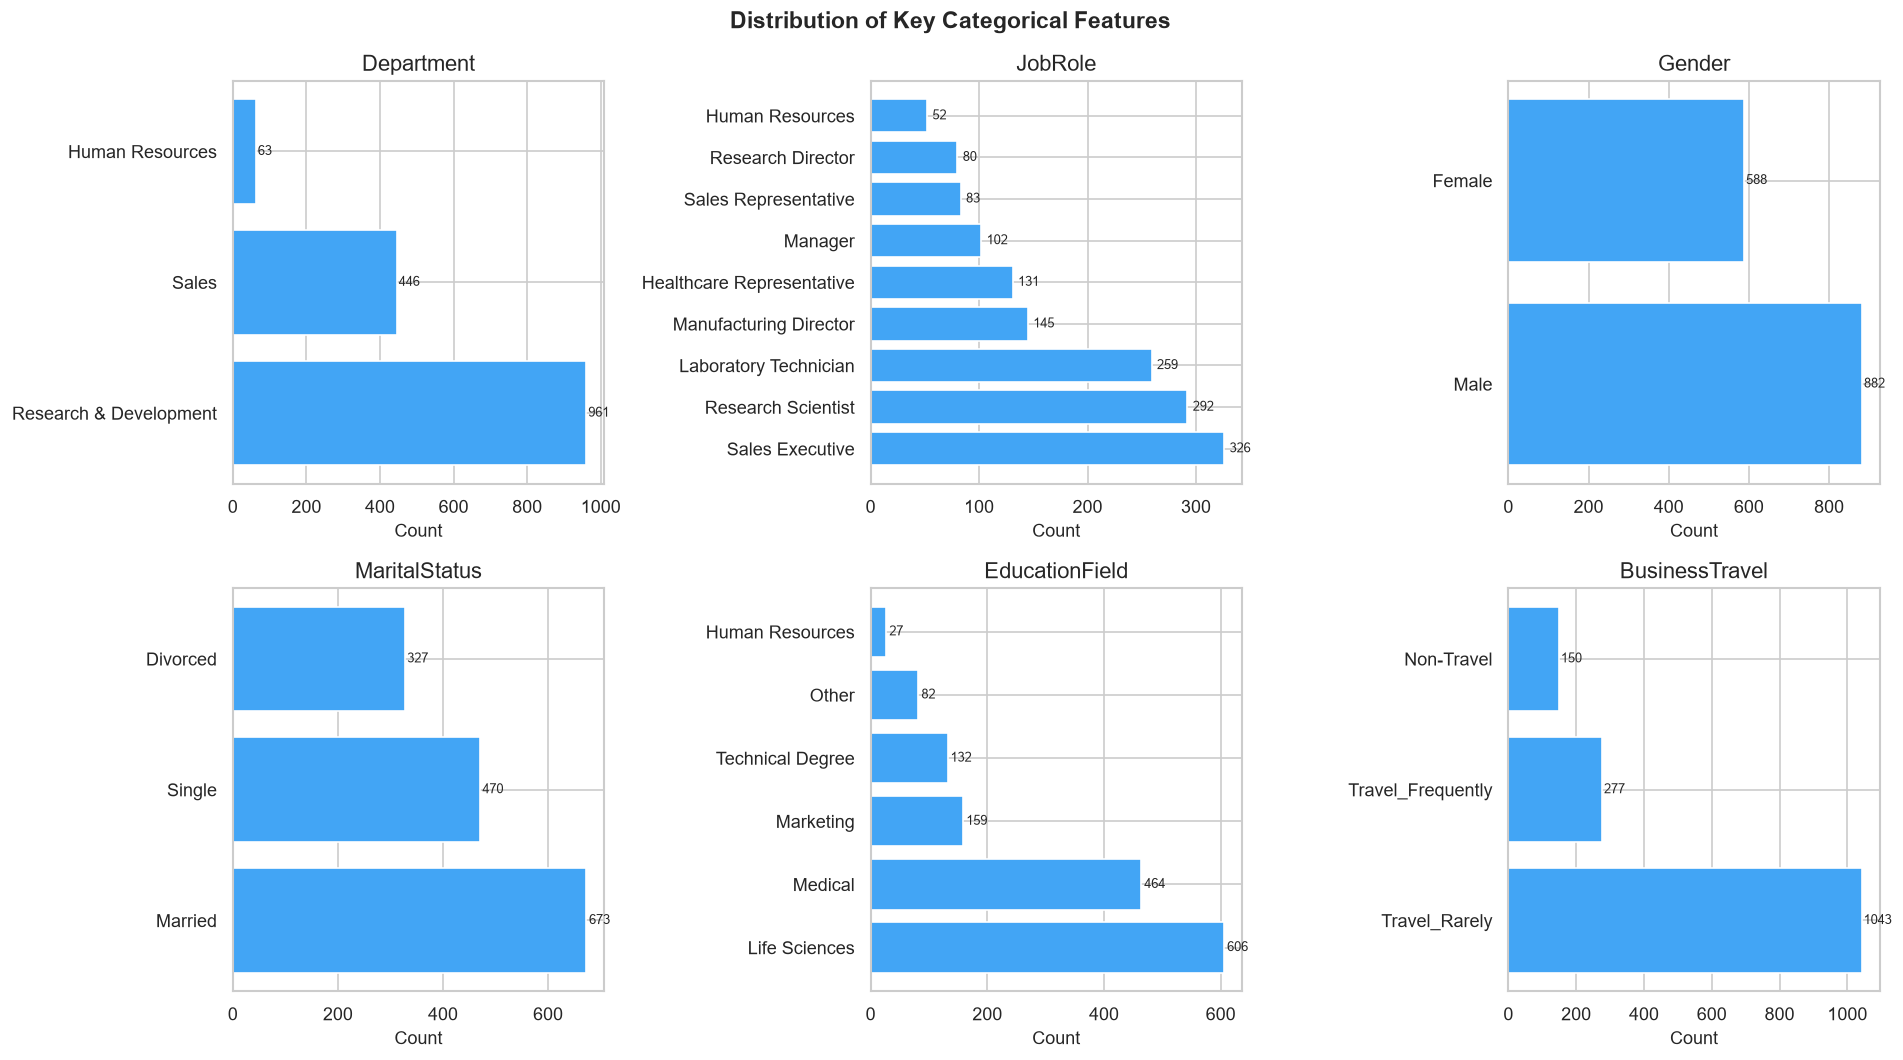

In [13]:
# Categorical feature distributions
key_cats = ['Department', 'JobRole', 'Gender', 'MaritalStatus', 'EducationField', 'BusinessTravel']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(key_cats):
    counts = df[col].value_counts()
    axes[i].barh(counts.index, counts.values, color='#42A5F5', edgecolor='white')
    axes[i].set_title(col)
    axes[i].set_xlabel('Count')
    for j, v in enumerate(counts.values):
        axes[i].text(v + 5, j, str(v), va='center', fontsize=8)

plt.suptitle('Distribution of Key Categorical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

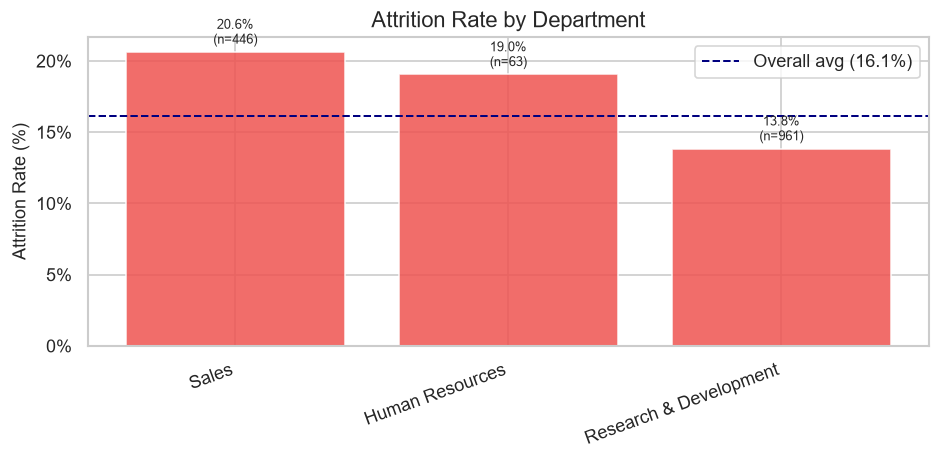

In [17]:
attrition_rate_by('Department')

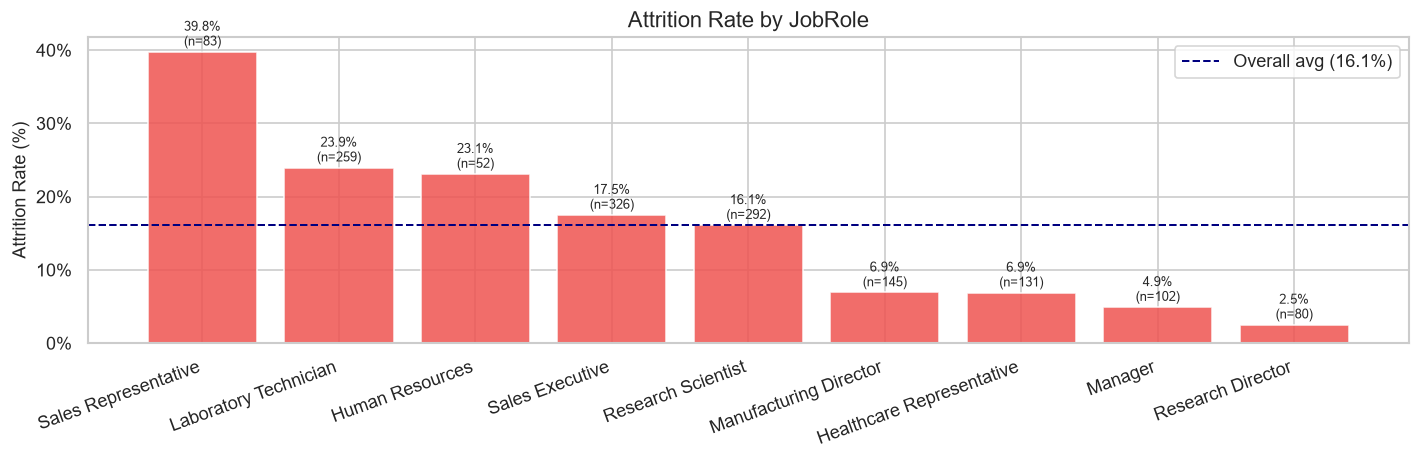

In [18]:
attrition_rate_by('JobRole', figsize=(12, 4))

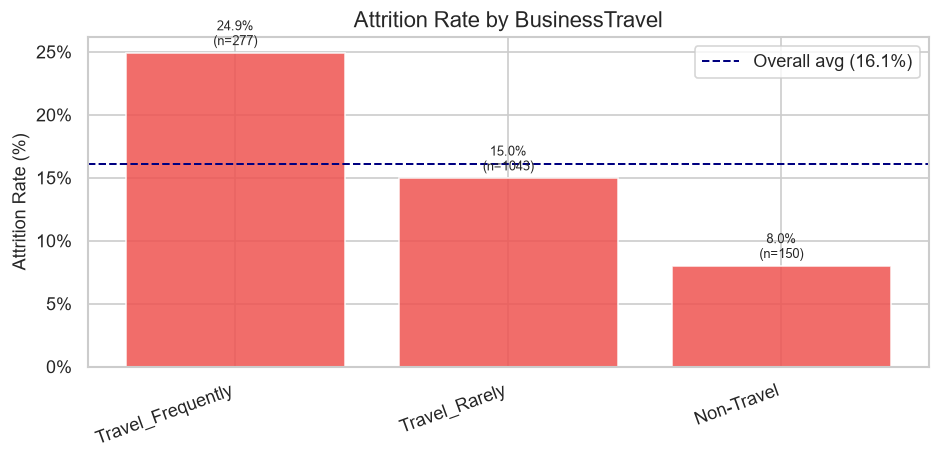

In [19]:
attrition_rate_by('BusinessTravel')

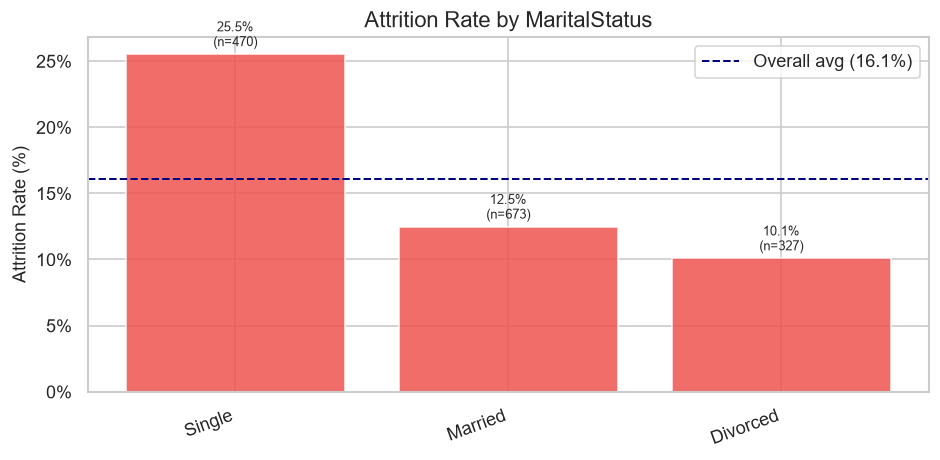

In [20]:
attrition_rate_by('MaritalStatus')

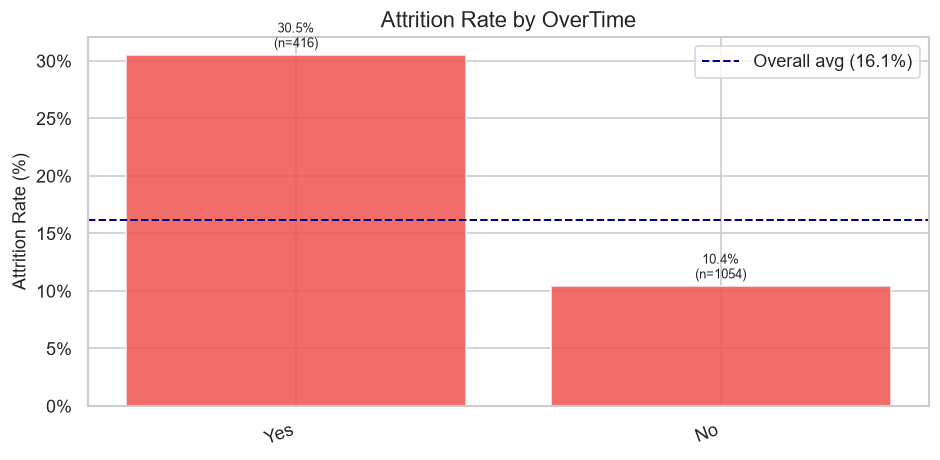

In [21]:
attrition_rate_by('OverTime')

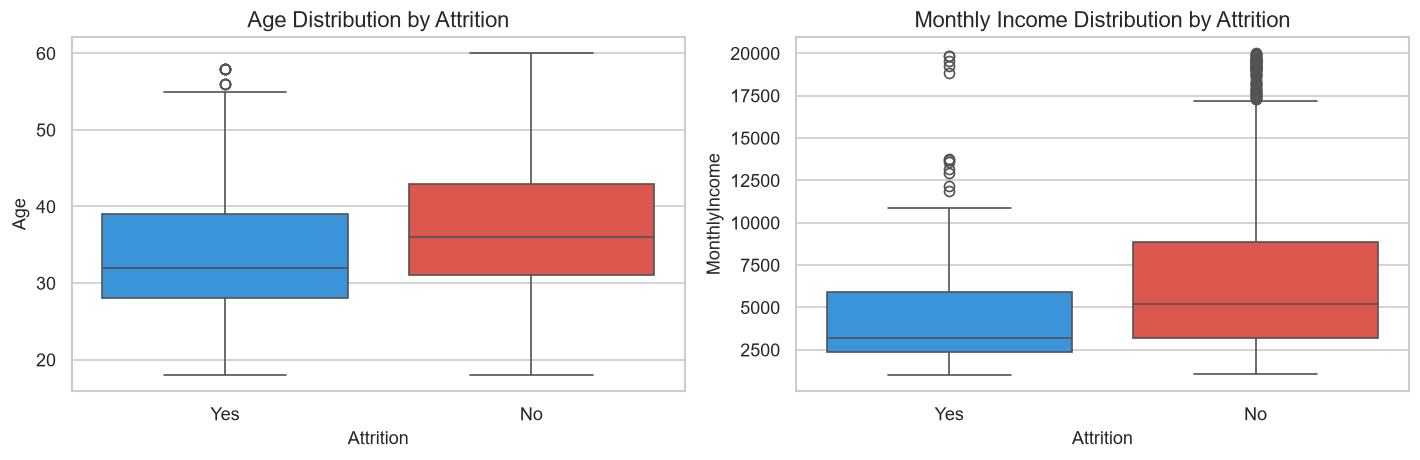

In [22]:
# Age vs Attrition — box plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x='Attrition', y='Age', palette=['#2196F3', '#F44336'], ax=axes[0])
axes[0].set_title('Age Distribution by Attrition')

sns.boxplot(data=df, x='Attrition', y='MonthlyIncome', palette=['#2196F3', '#F44336'], ax=axes[1])
axes[1].set_title('Monthly Income Distribution by Attrition')

plt.tight_layout()
plt.show()

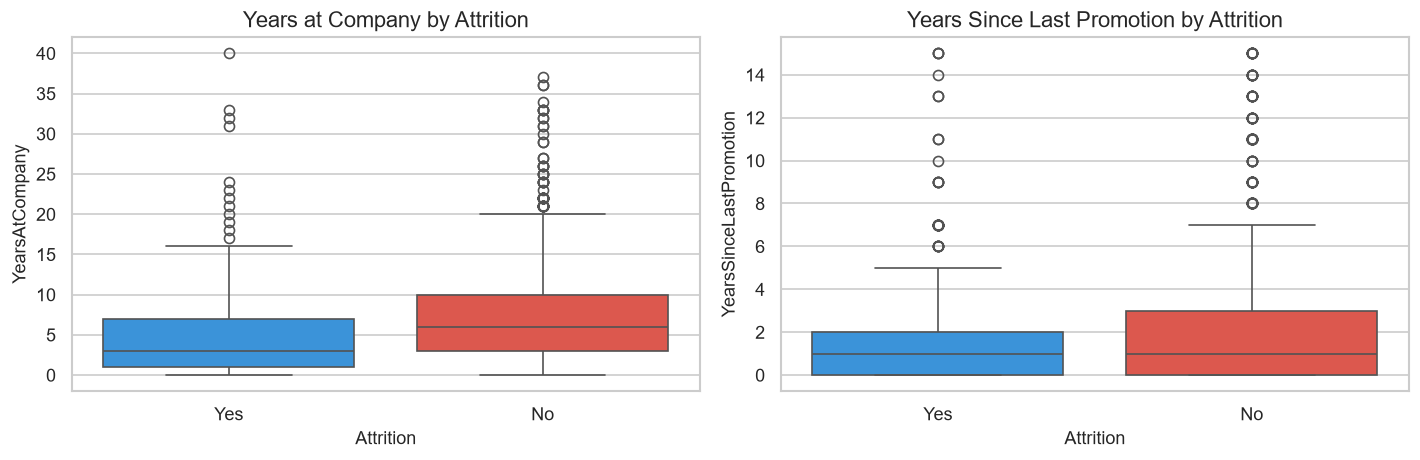

In [23]:
# Years at Company vs Attrition
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x='Attrition', y='YearsAtCompany', palette=['#2196F3', '#F44336'], ax=axes[0])
axes[0].set_title('Years at Company by Attrition')

sns.boxplot(data=df, x='Attrition', y='YearsSinceLastPromotion', palette=['#2196F3', '#F44336'], ax=axes[1])
axes[1].set_title('Years Since Last Promotion by Attrition')

plt.tight_layout()
plt.show()
